In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, roc_auc_score)
%matplotlib inline

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame
print(df.shape)
print(df["target"].value_counts().rename({0: "malignant", 1: "benign"}))
df.iloc[:, [0, 1, 2, -1]].head()

(569, 31)
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,target
0,17.99,10.38,122.80,0
1,20.57,17.77,132.90,0
2,19.69,21.25,130.00,0
3,11.42,20.38,77.58,0
4,20.29,14.34,135.10,0


In [3]:
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

Accuracy: 0.986


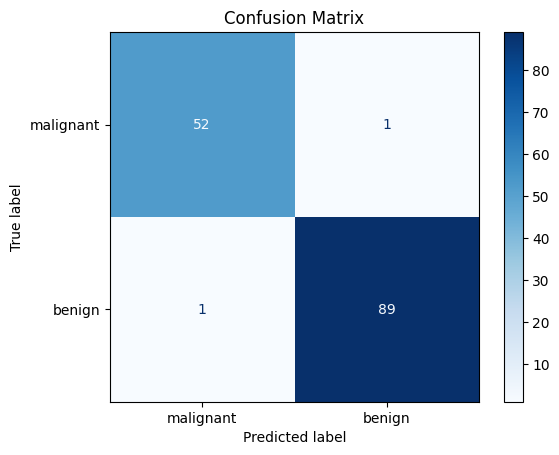

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



In [4]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(cmap="Blues")
plt.title("Confusion Matrix"); plt.show()

print(classification_report(y_test, y_pred, target_names=data.target_names))

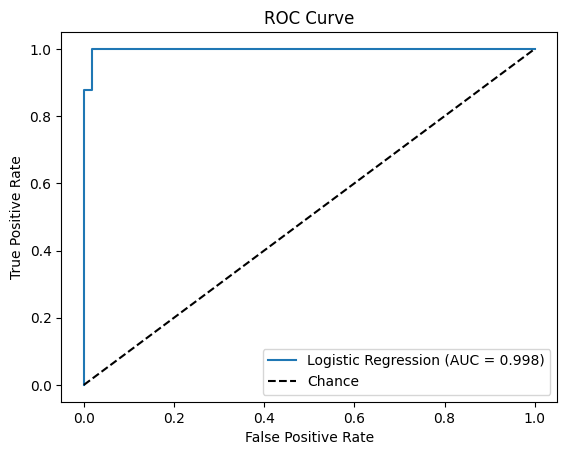

In [5]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(); plt.show()

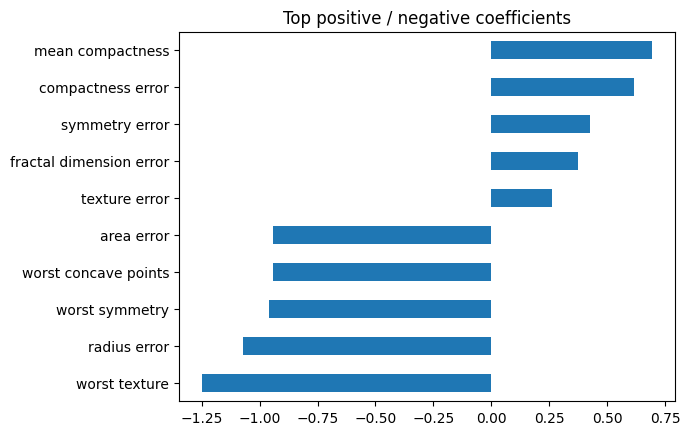

In [6]:
coefs = pd.Series(clf[-1].coef_[0], index=X.columns).sort_values()
pd.concat([coefs.head(5), coefs.tail(5)]).plot.barh(title="Top positive / negative coefficients")
plt.show()

(1797, 8, 8)


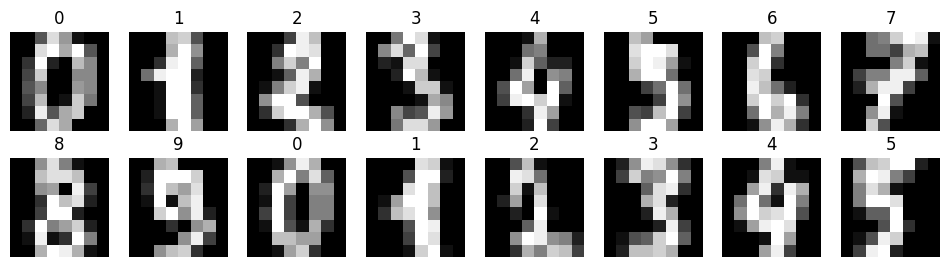

In [7]:
digits = load_digits()
print(digits.images.shape)

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for ax, img, lbl in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray"); ax.set_title(lbl); ax.axis("off")
plt.show()

In [8]:
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.25, random_state=0, stratify=digits.target)

dclf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
dclf.fit(Xd_train, yd_train)
yd_pred = dclf.predict(Xd_test)
print("Accuracy:", round(accuracy_score(yd_test, yd_pred), 4))
print(classification_report(yd_test, yd_pred))

Accuracy: 0.9689
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       0.87      0.98      0.92        46
           2       1.00      0.98      0.99        44
           3       0.96      1.00      0.98        46
           4       1.00      0.96      0.98        45
           5       0.98      0.93      0.96        46
           6       1.00      0.98      0.99        45
           7       0.98      1.00      0.99        45
           8       0.95      0.91      0.93        43
           9       0.98      0.96      0.97        45

    accuracy                           0.97       450
   macro avg       0.97      0.97      0.97       450
weighted avg       0.97      0.97      0.97       450



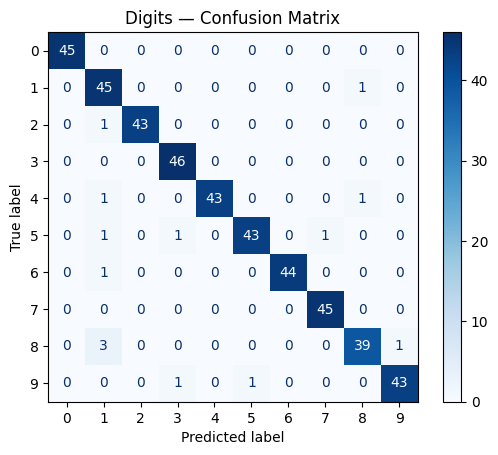

In [9]:
ConfusionMatrixDisplay.from_predictions(yd_test, yd_pred, cmap="Blues")
plt.title("Digits — Confusion Matrix"); plt.show()

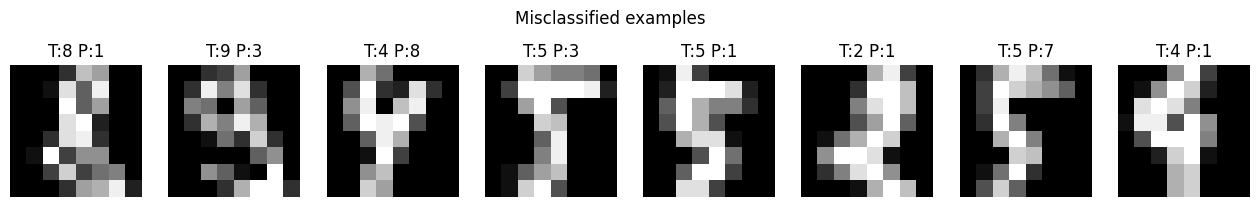

In [10]:
wrong = np.where(yd_pred != yd_test)[0][:8]
fig, axes = plt.subplots(1, len(wrong), figsize=(2*len(wrong), 2.5))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(Xd_test[i].reshape(8, 8), cmap="gray")
    ax.set_title(f"T:{yd_test[i]} P:{yd_pred[i]}"); ax.axis("off")
plt.suptitle("Misclassified examples"); plt.show()